In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('../../data/lung_cancer_dataset.csv')

In [3]:
df.head(10)

# radon_exposure is an ordinal variable
# family_history is a binary variable

,patient_id,age,gender,pack_years,radon_exposure,asbestos_exposure,secondhand_smoke_exposure,copd_diagnosis,alcohol_consumption,family_history,lung_cancer
0,100000,69,Male,66.025244,High,No,No,Yes,Moderate,No,No
1,100001,32,Female,12.780800,High,No,Yes,Yes,Moderate,Yes,Yes
2,100002,89,Female,0.408278,Medium,Yes,Yes,Yes,NaN,No,Yes
3,100003,78,Female,44.065232,Low,No,Yes,No,Moderate,No,Yes
4,100004,38,Female,44.432440,Medium,Yes,No,Yes,NaN,Yes,Yes
5,100005,100,Male,81.180545,Low,No,Yes,No,Moderate,Yes,Yes
6,100006,92,Male,18.156752,High,No,Yes,Yes,Moderate,Yes,Yes
7,100007,92,Male,27.511116,High,No,No,No,Moderate,No,Yes
8,100008,41,Female,7.824233,High,No,Yes,Yes,NaN,Yes,No
9,100009,20,Male,39.987504,Low,No,No,No,Moderate,No,No


In [4]:
df.shape

(50000, 11)

In [5]:
df.columns

Index(['patient_id', 'age', 'gender', 'pack_years', 'radon_exposure',
       'asbestos_exposure', 'secondhand_smoke_exposure', 'copd_diagnosis',
       'alcohol_consumption', 'family_history', 'lung_cancer'],
      dtype='str')

In [6]:
df.isnull().sum().reset_index()

,index,0
0,patient_id,0
1,age,0
2,gender,0
3,pack_years,0
4,radon_exposure,0
5,asbestos_exposure,0
6,secondhand_smoke_exposure,0
7,copd_diagnosis,0
8,alcohol_consumption,16662
9,family_history,0


In [7]:
df['gender'].value_counts()

gender
Female    25085
Male      24915
Name: count, dtype: int64

In [8]:
df['copd_diagnosis_binary'] = df['copd_diagnosis'].map({'Yes': 1, 'No': 0})
df

,patient_id,age,gender,pack_years,radon_exposure,asbestos_exposure,secondhand_smoke_exposure,copd_diagnosis,alcohol_consumption,family_history,lung_cancer,copd_diagnosis_binary
0,100000,69,Male,66.025244,High,No,No,Yes,Moderate,No,No,1
1,100001,32,Female,12.780800,High,No,Yes,Yes,Moderate,Yes,Yes,1
2,100002,89,Female,0.408278,Medium,Yes,Yes,Yes,NaN,No,Yes,1
3,100003,78,Female,44.065232,Low,No,Yes,No,Moderate,No,Yes,0
4,100004,38,Female,44.432440,Medium,Yes,No,Yes,NaN,Yes,Yes,1
...,...,...,...,...,...,...,...,...,...,...,...,...
49995,149995,81,Female,9.386431,Medium,No,Yes,No,Moderate,No,Yes,0
49996,149996,28,Male,99.471718,Medium,No,Yes,No,Moderate,No,Yes,0
49997,149997,90,Male,14.349722,Low,Yes,Yes,No,Heavy,Yes,Yes,0
49998,149998,33,Female,87.012555,Medium,No,No,Yes,Moderate,No,No,1


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   patient_id                 50000 non-null  int64  
 1   age                        50000 non-null  int64  
 2   gender                     50000 non-null  str    
 3   pack_years                 50000 non-null  float64
 4   radon_exposure             50000 non-null  str    
 5   asbestos_exposure          50000 non-null  str    
 6   secondhand_smoke_exposure  50000 non-null  str    
 7   copd_diagnosis             50000 non-null  str    
 8   alcohol_consumption        33338 non-null  str    
 9   family_history             50000 non-null  str    
 10  lung_cancer                50000 non-null  str    
 11  copd_diagnosis_binary      50000 non-null  int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 4.6 MB


In [10]:
df['alcohol_consumption'].value_counts()

alcohol_consumption
Heavy       16762
Moderate    16576
Name: count, dtype: int64

In [11]:
df_missing = df.copy()

In [12]:
import numpy as np

In [13]:
df_missing.loc[0, "age"] = np.nan

In [14]:
df_missing.isnull().sum().reset_index()

,index,0
0,patient_id,0
1,age,1
2,gender,0
3,pack_years,0
4,radon_exposure,0
5,asbestos_exposure,0
6,secondhand_smoke_exposure,0
7,copd_diagnosis,0
8,alcohol_consumption,16662
9,family_history,0


In [15]:
df_missing['age'].mean()

58.85683713674273

In [16]:
df_missing['age'] = df_missing['age'].fillna(df_missing['age'].mean())

In [17]:
# df_missing.dropna(inplace=True, subset=['age'])

In [18]:
df_missing

,patient_id,age,gender,pack_years,radon_exposure,asbestos_exposure,secondhand_smoke_exposure,copd_diagnosis,alcohol_consumption,family_history,lung_cancer,copd_diagnosis_binary
0,100000,58.856837,Male,66.025244,High,No,No,Yes,Moderate,No,No,1
1,100001,32.000000,Female,12.780800,High,No,Yes,Yes,Moderate,Yes,Yes,1
2,100002,89.000000,Female,0.408278,Medium,Yes,Yes,Yes,NaN,No,Yes,1
3,100003,78.000000,Female,44.065232,Low,No,Yes,No,Moderate,No,Yes,0
4,100004,38.000000,Female,44.432440,Medium,Yes,No,Yes,NaN,Yes,Yes,1
...,...,...,...,...,...,...,...,...,...,...,...,...
49995,149995,81.000000,Female,9.386431,Medium,No,Yes,No,Moderate,No,Yes,0
49996,149996,28.000000,Male,99.471718,Medium,No,Yes,No,Moderate,No,Yes,0
49997,149997,90.000000,Male,14.349722,Low,Yes,Yes,No,Heavy,Yes,Yes,0
49998,149998,33.000000,Female,87.012555,Medium,No,No,Yes,Moderate,No,No,1


In [19]:
df.duplicated().sum()

0

In [20]:
df["age"].describe()

count    50000.000000
mean        58.857040
std         23.958266
min         18.000000
25%         38.000000
50%         59.000000
75%         80.000000
max        100.000000
Name: age, dtype: float64

In [21]:
age_range = df["age"].max() - df["age"].min()
age_range

82

In [22]:
Q1 = df["age"].quantile(0.25)
Q2 = df["age"].quantile(0.5)
Q3 = df["age"].quantile(0.75)
IQR = Q3 - Q1

Text(0.5, 1.0, 'Boxplot of Age')

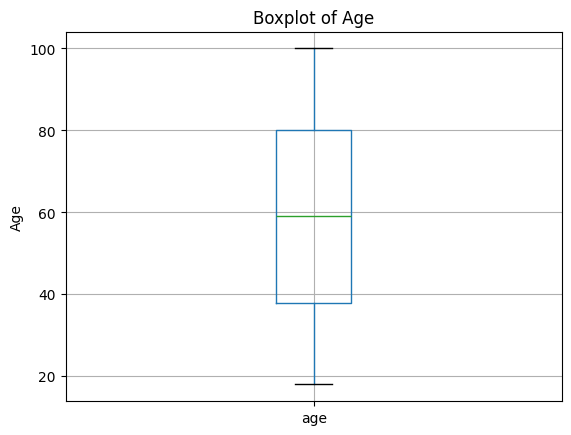

In [23]:
import matplotlib.pyplot as plt

df.boxplot(column='age')
plt.ylabel('Age')
plt.title('Boxplot of Age')

In [24]:
population_mean = df["age"].mean()
population_mean

58.85704

In [25]:
sample1 = df["age"].sample(n=30)
sample1.mean()

62.233333333333334

In [26]:
sample1.shape

(30,)

In [27]:
small_sample = df["age"].sample(n=10, random_state=42)
small_sample.mean()

43.9

In [28]:
large_sample = df["age"].sample(n=100, random_state=42)
large_sample.mean()

54.51

In [29]:
df['age'].mean()

58.85704

In [33]:
sample_means = []

for i in range(5000):
    sample = df['age'].sample(n=30, random_state=i, replace=True)
    sample_means.append(sample.mean())

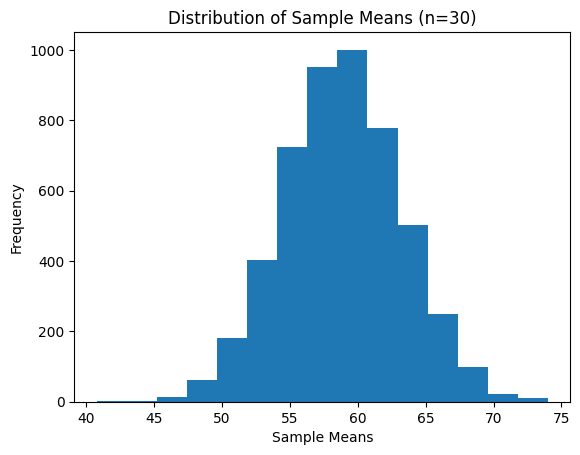

In [34]:
plt.hist(sample_means, bins=15)

plt.xlabel('Sample Means')
plt.ylabel('Frequency')
plt.title('Distribution of Sample Means (n=30)')
plt.show()

In [36]:
df['age'].mean()

58.85704

In [42]:
sample = df['age'].sample(n=40, random_state=10)
sample.mean()

59.2

In [43]:
sample_mean = sample.mean()
differnece = sample_mean - 60

In [44]:
print(f"Sample Mean: {sample_mean}")
print(f"Difference from Population Mean (60): {differnece}")

Sample Mean: 59.2
Difference from Population Mean (60): -0.7999999999999972


In [45]:
s = sample.std()
n = len(sample)

In [46]:
SE = s / np.sqrt(n)

In [47]:
print(f"Sample Mean: {sample_mean}")
print(f"Sample Standard Deviation: {s}")
print(f"Sample Size: {n}")
print(f"Standard Error: {SE}")

Sample Mean: 59.2
Sample Standard Deviation: 23.429326352529504
Sample Size: 40
Standard Error: 3.7045017658699173


In [48]:
t_stat = differnece / SE

In [49]:
print(f"t_statistic: {t_stat}")

t_statistic: -0.215953467041238


In [50]:
from scipy.stats import ttest_1samp

In [52]:
t_stat, p_value = ttest_1samp(sample, 60)
print(f"t_statistic: {t_stat}")
print(f"p_value: {p_value}")

t_statistic: -0.21595346704123802
p_value: 0.8301495553380196


In [60]:
age_cancer = df.loc[df['lung_cancer'] == 'Yes']['age'].sample(n=50, random_state=10)
age_no_cancer = df.loc[df['lung_cancer'] == 'No', 'age'].sample(n=50, random_state=10)

In [62]:
print(f"Cancer group mean: {age_cancer.mean()}")
print(f"No cancer group mean: {age_no_cancer.mean()}")

Cancer group mean: 63.84
No cancer group mean: 50.96


In [63]:
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(age_cancer, age_no_cancer, equal_var=False)

print(f"t_statistic: {t_stat}")
print(f"p_value: {p_value}")

t_statistic: 2.8664969160790554
p_value: 0.005080620354818167
